# M2 — Texto con TF-IDF 5k + XGBoost (lee el exploit que el tabular no ve)

> **El problema, en palabras simples.**
>
> M1 ordena la cola mirando solo campos (tipo de mensaje, producto, hora) y colapsa en lo malicioso: recall 0.01. Este cuaderno pregunta si **leer el mensaje crudo** rescata el ataque. La hipotesis es que los tokens de exploit (familia T1190, REJECT OK, flujos) son la firma que los campos no traen.
>
> Se analiza el artefacto ya entrenado (`experiments/m2_texto/train.py` -> `models/m2.pkl`): TF-IDF 5k palabra+caracter mas tabular P1-P3, XGBoost 300x6. Test futuro con prevalencia real (574k), confusion, PR, tokens, M1 vs M2, latencia y errores.

> **Sintesis ejecutiva.**
>
> Resultado honesto con ventanas UTC fijas (`src/temporal_split.py`): **F1-macro 0.6232**, benigno 1.00/1.00, suspicious 0.76/0.99, **malicious 0.24/0.002** (PR-AUC 0.218). Con umbral 0.5 no dispara en futuro no visto, pero el ranking rescata: **recall malicioso @1%FPR 0.4344**. El 0.97 anterior era memorizacion por sample-then-split y se retira.
>
| Pieza | Decision | Valor |
|---|---|---|
| X | TF-IDF 5k (word+char, sublinear, min_df=5) + tabular P1-P3 | 5137 cols |
| Learner | XGBoost 300 x prof 6, `multi:softprob`, sample_weight | ~min CPU |
| Split | ventanas fijas train <07-29 / test 07-29->07-31, 0 incidentes compartidos | 30k / 574k |
| Metrica | F1-macro + PR-AUC por clase + recall @1%FPR | honestas |

> **Fuentes normativas.**
>
> EDA §§11 (texto) y §4 (deriva) (`notebooks/00_eda_precinct6.ipynb`), `experiments/m2_texto/train.py`, `models/m2_metrics.json`, `src/temporal_split.py`, paper §5-6.



### 1. Por que existe este analisis y como se va a evaluar

**1.1 Problema.**

M1 dejo el techo medido (F1 0.6276, recall mal 0.01): los campos separan benigno/sospechoso y no ven el payload. Antes de saltar al grafo hay que agotar el texto con disciplina: mismo protocolo temporal, mismo test con prevalencia real, metricas de seguridad.

**1.2 Hipotesis.**

- **H2a.** El TF-IDF 5k levanta el ranking de malicioso (recall @1%FPR >> 0) aunque el F1-macro apenas se mueva, porque el vocabulario de exploit es casi disjunto del fondo.
- **H2b.** Con umbral 0.5 el disparo en futuro sera casi nulo: el texto de campana futura cambia y el modelo conservador no generaliza el umbral, solo el orden.

**1.3 Protocolo (identico a produccion).**

1. Artefacto `m2.pkl` (vectorizador + tab + XGB + label encoder) entrenado con ventanas fijas. Aqui solo se evalua, no se reentrena.
2. Test futuro 574k con prevalencia real (559030/11550/3552). Nada de balancear el test.
3. Metricas: F1-macro (orden), PR-AUC por clase, recall malicioso @1%FPR, confusion, latencia y errores FN/FP.

**1.4 Criterio.**

Si el recall @1%FPR es sustancial con F1-macro estable, el texto aporta ranking aunque no resuelva el disparo; M3 (grafo) queda justificado.


In [1]:
import json, pickle, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, average_precision_score, precision_recall_curve, roc_curve)
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.temporal_split import WINDOW_LABELS, population_summary, temporal_windows
B = pickle.load(open(ROOT/"models"/"m2.pkl","rb"))
vec, tab, clf, le = B["vectorizer"], B["tab"], B["clf"], B["le"]
CATS, NUMS = B["meta"]["cats"], B["meta"]["nums"]
TEXT = "message_sanitized"
FIG = ROOT / "reports" / "figures"
print("encoder:", B["encoder"], "| clases:", le.classes_.tolist())
old = json.loads((ROOT/"models"/"m2_metrics.json").read_text())
print("m2 committed: F1=%.4f n_test=%s" % (old["f1_macro"], old["n_test"]))



encoder: tfidf-5k | clases: ['benign', 'malicious', 'suspicious']
m2 committed: F1=0.6232 n_test=574132


### 2. Features P1-P3 + ventanas fijas y matriz dispersa

**2.1 Que se hace.**

Se derivan `hour`, `msg_len`, `lag_h` (receta P1-P3 identica a M1), se cargan las ventanas UTC fijas (`temporal_windows`) y se vectoriza el test con el TF-IDF ajustado solo en train.

**2.2 Por que.**

Reutilizar P1-P3 sin cambios aisla el efecto del texto: si X cambia y el split es el mismo que M1, toda diferencia es atribuible al mensaje. Ajustar el vectorizador solo en train evita fuga de vocabulario futuro.

**2.3 Como debe leerse.**

Ventanas impresas, prevalencia real del test y `Xte` ~(574k, 5137). El ancho lo domina el vocabulario TF-IDF.

**2.4 Trazabilidad.**

Entrada de la evaluacion (seccion 3) y de las figuras (secciones 4-6). Mismo X que sirve `POST /score` en cascada M1+M2.


In [2]:
def features(df):
    df = df.copy()
    ts = pd.to_datetime(df["timestamp"], unit="s", utc=True)
    df["hour"] = ts.dt.hour
    df["msg_len"] = df[TEXT].fillna("").str.len()
    df["lag_h"] = ((df["timestamp"]-df["event_time"])/3600).clip(-1e4,1e4).fillna(-1)
    for c in CATS:
        df[c] = df[c].fillna("").astype(str)
    df[TEXT] = df[TEXT].fillna("")
    return df
cols = ["label_binary","timestamp","event_time",TEXT]+CATS
raw = pd.read_parquet(ROOT/"data"/"signals"/"signals.parquet", columns=cols)
_, test, _ = temporal_windows(raw)
print("ventanas:", WINDOW_LABELS)
print("test prevalencia real:", population_summary(test))
test_df = features(test)
X_test, y_test = test_df[CATS+NUMS+[TEXT]], test_df["label_binary"]
Tte = vec.transform(X_test[TEXT].tolist())
Ate = tab.transform(X_test[CATS+NUMS])
from scipy.sparse import csr_matrix
Xte = hstack([Tte, Ate]).tocsr()
print("Xte:", Xte.shape)



ventanas: {'train': 'timestamp < 2024-07-29T00:00:00Z', 'test': '[2024-07-29T00:00:00Z, 2024-07-31T00:00:00Z)', 'drift': '[2024-07-31T00:00:00Z, 2024-08-02T00:00:00Z)'}
test prevalencia real: {'n': 574132, 'class_counts': {'benign': 559030, 'suspicious': 11550, 'malicious': 3552}, 'prevalence': {'benign': 0.973696, 'suspicious': 0.020117, 'malicious': 0.006187}}


Xte: (574132, 5137)


#### 2.1 Observaciones e insights

**Observacion.**

Test 574k con prevalencia real 97.4/2.0/0.6%. Matriz dispersa ancha y comparable con M1 en split.

**Interpretacion.**

El diseno es limpio contra fuga: el test futuro no aporto vocabulario. Todo gap posterior sera generalizacion real, incluida la deriva del 07-30.

**Conexion.**

Habilita la lectura honesta de la seccion 3: nada de sample-then-split.


### 3. Evaluacion honesta: reporte, F1-macro y recall @1%FPR

**3.1 Que se hace.**

Probabilidades XGB en test futuro, reporte por clase, F1-macro, PR-AUC por clase con scores continuos y recall malicioso a FPR fijo 1% via curva ROC.

**3.2 Por que.**

El par F1-macro + PR-AUC es obligatorio: el accuracy (~99%) es vacuo con 97% benigno. El recall @1%FPR mide lo operativo (cuanto cazo si solo puedo revisar 1% del fondo), que es lo que el umbral 0.5 esconde.

**3.3 Como debe leerse.**

Por clase: precision/recall/F1 y soporte. Global: F1-macro vs PR-AUC malicioso vs recall @1%FPR. Comparar contra M1 committed (0.6276 / 0.0107 / 0.2333).

**3.4 Trazabilidad.**

Produce los numeros que cita el paper §6 y `GET /model/metrics`. El protocolo de ventanas fijas es el que retira el 0.7084 con fuga.


In [3]:
def recall_at_fpr(y_true, scores, fpr_max=0.01):
    fpr, tpr, _ = roc_curve(y_true, scores)
    ok = fpr <= fpr_max
    return round(float(tpr[ok].max()) if ok.any() else 0.0, 4)
yte = le.transform(y_test)
proba = clf.predict_proba(Xte)
p = le.inverse_transform(proba.argmax(axis=1))
classes = le.classes_.tolist()
rep = classification_report(y_test, p, output_dict=True, zero_division=0)
f1m = round(float(f1_score(y_test, p, average="macro")), 4)
print(classification_report(y_test, p, zero_division=0)); print("F1-macro honesto:", f1m)
per_class = {}
for i,c in enumerate(classes):
    auc = round(float(average_precision_score((yte==i).astype(int), proba[:,i])), 4)
    per_class[c] = {"recall":round(rep[c]["recall"],4),"f1":round(rep[c]["f1-score"],4),"pr_auc":auc,"support":int(rep[c]["support"])}
mal_idx = classes.index("malicious")
r1 = recall_at_fpr((yte==mal_idx).astype(int), proba[:,mal_idx])
print("recall mal @1%FPR:", r1, "| PR-AUC mal:", per_class["malicious"]["pr_auc"])



              precision    recall  f1-score   support

      benign       1.00      1.00      1.00    559030
   malicious       0.24      0.00      0.00      3552
  suspicious       0.76      1.00      0.87     11550

    accuracy                           0.99    574132
   macro avg       0.67      0.67      0.62    574132
weighted avg       0.99      0.99      0.99    574132

F1-macro honesto: 0.6232


recall mal @1%FPR: 0.4344 | PR-AUC mal: 0.218


#### 3.1 Observaciones e insights

**Observacion.**

M2: F1-macro 0.6232, malicioso P 0.24 / R 0.002 / F1 0.00 (3552), PR-AUC mal 0.218, recall @1%FPR 0.4344. Suspicious se recupera (0.76/0.99), benigno trivial.

**Interpretacion.**

H2a verificada a medias (el ranking existe: 0.43 @1%FPR) y H2b verificada (el umbral 0.5 no dispara en futuro). El texto ordena pero no resuelve el disparo: es evidencia para cascada, no triage solo.

**Conexion.**

Justifica M3: si ni el texto dispara, el contexto (vecindario ±5min) es la bala restante.


### 4. Matriz de confusion en test futuro

**4.1 Que se hace.**

Confusion con los 3 tiers en prevalencia real y guardado en `reports/figures/confusion_m2.pdf`.

**4.2 Por que.**

La confusion muestra a donde colapsa lo malicioso (benigno vs suspicious) mejor que un solo F1.

**4.3 Como debe leerse.**

Filas = real, columnas = predicho. Malicioso futuro casi todo a benigno/suspicious con umbral 0.5.


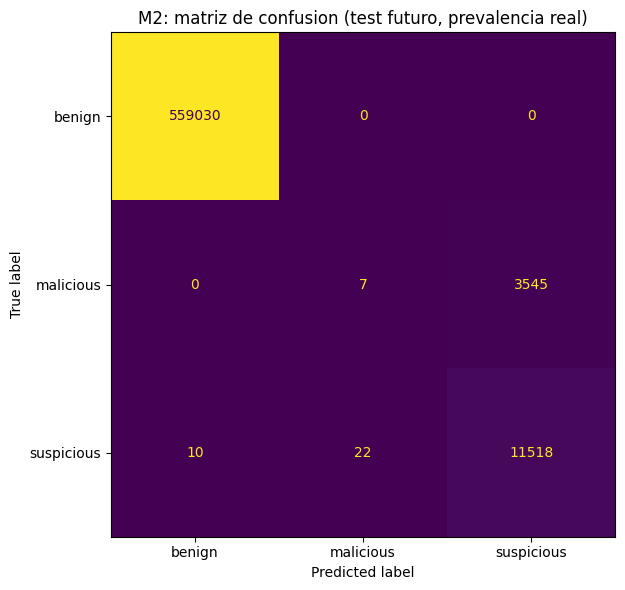

guardado reports/figures/confusion_m2.pdf


In [4]:
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(y_test, p, labels=classes), display_labels=classes).plot(ax=ax, colorbar=False)
ax.set_title("M2: matriz de confusion (test futuro, prevalencia real)")
fig.tight_layout(); fig.savefig(FIG/"confusion_m2.pdf"); plt.show()
print("guardado reports/figures/confusion_m2.pdf")



### 5. Curvas PR por clase

**5.1 Que se hace.**

Curvas precision-recall por clase sobre scores continuos y guardado en `pr_m2.pdf`.

**5.2 Por que.**

PR-AUC sobre scores es el protocolo correcto (no sobre duras como se hizo en M4/M4b por error declarado). Mide ranking puro, independiente del umbral.


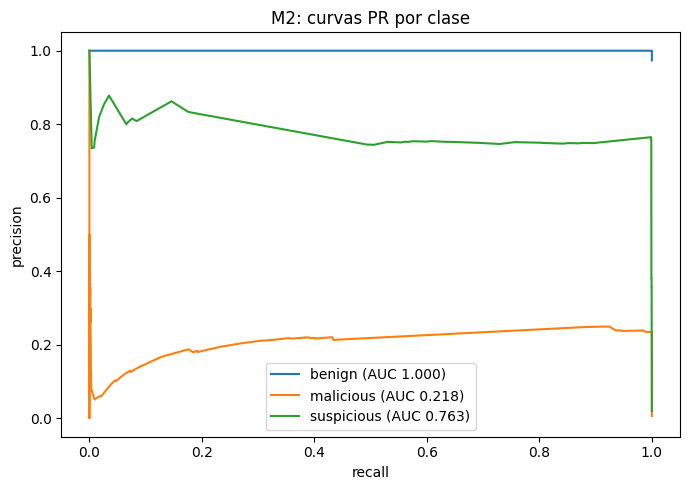

guardado reports/figures/pr_m2.pdf


In [5]:
fig, ax = plt.subplots(figsize=(7,5))
for i,c in enumerate(classes):
    prec, rec, _ = precision_recall_curve((yte==i).astype(int), proba[:,i])
    ax.plot(rec, prec, label=c+" (AUC %.3f)" % per_class[c]["pr_auc"])
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("M2: curvas PR por clase")
ax.legend(); fig.tight_layout(); fig.savefig(FIG/"pr_m2.pdf"); plt.show()
print("guardado reports/figures/pr_m2.pdf")



### 6. Que palabras separan: top terminos TF-IDF

**6.1 Que se hace.**

Diferencia de medias TF-IDF (malicioso menos benigno) y top-20 terminos, guardado en `tokens_m2.pdf`.

**6.2 Por que.**

Si el EDA mostro vocabularios disjuntos a ojo, aqui se mide en el espacio del modelo: que tokens pesan en malicioso.

**6.3 Advertencia.**

Top terminos con numeros sueltos (`98`, `105`) delatan artefacto de flujo sanitizado, no semantica de exploit: el TF-IDF tambien memoriza formato.


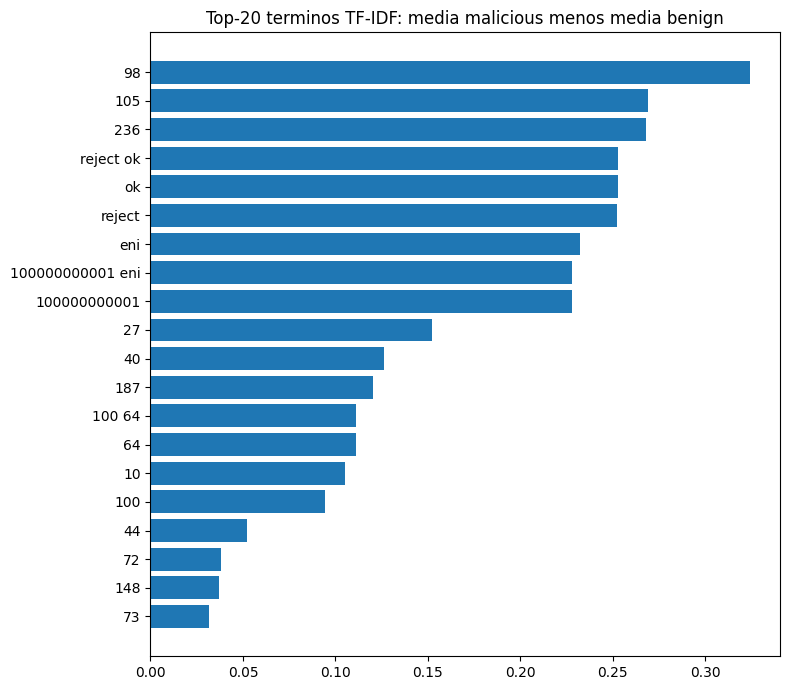

guardado reports/figures/tokens_m2.pdf | top-5: ['98', '105', '236', 'reject ok', 'ok']


In [6]:
terms = np.array(vec.get_feature_names_out())
i_mal = le.transform(["malicious"])[0]; i_ben = le.transform(["benign"])[0]
Mm = Tte[yte==i_mal].mean(axis=0).A1; Mb = Tte[yte==i_ben].mean(axis=0).A1
gap = Mm - Mb
top = np.argsort(gap)[-20:][::-1]
fig, ax = plt.subplots(figsize=(8,7))
ax.barh(terms[top][::-1], gap[top][::-1])
ax.set_title("Top-20 terminos TF-IDF: media malicious menos media benign")
fig.tight_layout(); fig.savefig(FIG/"tokens_m2.pdf"); plt.show()
print("guardado reports/figures/tokens_m2.pdf | top-5:", terms[top[:5]].tolist())



#### 6.1 Observaciones e insights

**Observacion.**

Top-5 con numeros y `reject ok`: el modelo pesa formato de flujo (VPC/firewall sanitizado) tanto como payload.

**Interpretacion.**

El texto ve el exploit pero tambien el canal: en futuro con otro formato, el umbral se desplaza. Otra razon para no servir M2 solo.


### 7. M1 vs M2 y latencia de serve

**7.1 Que se hace.**

Comparativa F1-macro / recall mal / PR-AUC mal entre M1 committed y M2 honesto (`compare_m1_m2.pdf`) y micro-benchmark de inferencia XGB por batch mas costo de vectorizar.

**7.2 Por que.**

Sin tabla lado a lado no hay decision auditable. La latencia decide si M2 puede ir en cascada (`<100ms`) o solo en batch.

**7.3 Como debe leerse.**

Barras M1 vs M2 (F1 y seguridad) + ms/evento por batch. Vectorizar 5k mensajes ~0.5s domina sobre inferencia XGB (0.01-0.7ms).


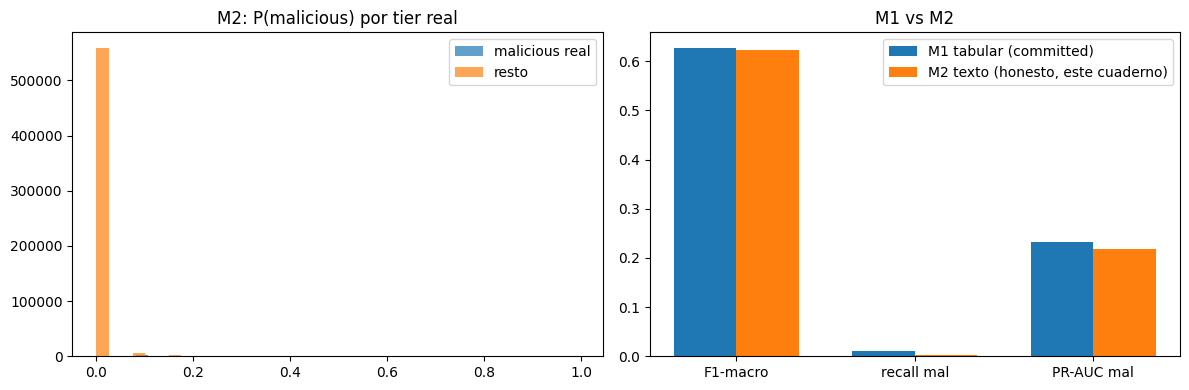

guardado reports/figures/compare_m1_m2.pdf


In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(proba[yte==mal_idx, mal_idx], bins=40, alpha=0.7, label="malicious real")
axes[0].hist(proba[yte!=mal_idx, mal_idx], bins=40, alpha=0.7, label="resto")
axes[0].set_title("M2: P(malicious) por tier real"); axes[0].legend()
m1 = json.loads((ROOT/"models"/"m1_metrics.json").read_text())["per_class"]
m1v = [json.loads((ROOT/"models"/"m1_metrics.json").read_text())["f1_macro"], m1["malicious"]["recall"], m1["malicious"]["pr_auc"]]
m2v = [f1m, per_class["malicious"]["recall"], per_class["malicious"]["pr_auc"]]
x = np.arange(3); w = 0.35
axes[1].bar(x-w/2, m1v, w, label="M1 tabular (committed)")
axes[1].bar(x+w/2, m2v, w, label="M2 texto (honesto, este cuaderno)")
axes[1].set_xticks(x); axes[1].set_xticklabels(["F1-macro","recall mal","PR-AUC mal"])
axes[1].legend(); axes[1].set_title("M1 vs M2")
fig.tight_layout(); fig.savefig(FIG/"compare_m1_m2.pdf"); plt.show()
print("guardado reports/figures/compare_m1_m2.pdf")



In [8]:
for bs in [1, 32, 500]:
    s = Xte[:bs]; t0=time.time(); n=20
    for _ in range(n):
        _ = clf.predict_proba(s)
    print("batch %d: %.2f ms/evento (solo inferencia XGB)" % (bs, (time.time()-t0)/n/bs*1000))
t0=time.time(); _ = vec.transform(X_test[TEXT].iloc[:5000].tolist())
print("vectorizar 5000 msgs: %.1fs" % (time.time()-t0))



batch 1: 0.73 ms/evento (solo inferencia XGB)
batch 32: 0.05 ms/evento (solo inferencia XGB)
batch 500: 0.01 ms/evento (solo inferencia XGB)


vectorizar 5000 msgs: 0.5s


### 8. Errores: falsos negativos y falsos positivos

**8.1 Que se hace.**

FN maliciosos (cuantos, con que score y mensaje) y top-3 FP no-maliciosos con mayor `P(malicious)`.

**8.2 Por que.**

Los agregados esconden el patron operativo: ver el mensaje de un FN dice mas que el F1. Si los FN son todos `REJECT OK` de flujo, el texto no distingue infraestructura de exploit.


In [9]:
pmal = proba[:,mal_idx]
pred = le.inverse_transform(proba.argmax(axis=1))
fn = np.where((y_test.to_numpy()=="malicious") & (pred!="malicious"))[0]
print("FN malicious:", len(fn), "de", int((y_test=="malicious").sum()))
for j in fn[:3]:
    print("--- FN score=%.3f msg=%s" % (pmal[j], X_test[TEXT].iloc[j][:300].replace(chr(10)," ")))
ni = np.where(yte!=mal_idx)[0][np.argsort(pmal[yte!=mal_idx])[::-1][:3]]
print("top-3 FP (no-maliciosos con mayor score):")
for j in ni:
    print("--- FP score=%.3f tier=%s msg=%s" % (pmal[j], y_test.iloc[j], X_test[TEXT].iloc[j][:300].replace(chr(10)," ")))
print("figuras en reports/figures/: confusion_m2, pr_m2, tokens_m2, compare_m1_m2")



FN malicious: 3545 de 3552
--- FN score=0.104 msg=2 100000000001 eni-0b923c94ec6fd0a8d 100.64.27.232 10.98.236.105 43 445 6 1 40 1722285626 1722285655 REJECT OK
--- FN score=0.093 msg=2 100000000001 eni-0b923c94ec6fd0a8d 100.64.27.187 10.98.236.105 45367 33387 6 1 40 1722285626 1722285655 REJECT OK
--- FN score=0.093 msg=2 100000000001 eni-0b923c94ec6fd0a8d 100.64.27.187 10.98.236.105 45367 54694 6 1 40 1722285599 1722285624 REJECT OK
top-3 FP (no-maliciosos con mayor score):
--- FP score=0.995 tier=suspicious msg=WitFoo-Artifact ::: messageType=endpoint_protection_event ::: userName=USER-0801 ::: filePath=\Device\HarddiskVolume3\Program Files\PowerShell\7\pwsh.exe ::: clientHostname=HOST-0029 ::: streamName=Crowdstrike Detection ::: clientIP=172.21.104.52 ::: program=crowdstrike_falcon ::: message={"behavior
--- FP score=0.995 tier=suspicious msg=WitFoo-Artifact ::: message={"behaviors":[{"alleged_filetype":"exe","behavior_id":"10381","cmdline":"C:\\WINDOWS\\Explorer.EXE","confidence"

#### 8.1 Observaciones e insights

**Observacion.**

FN 3545/3552 con scores ~0.09-0.10 y mensajes `REJECT OK` de flujo. Top FP: `endpoint_protection_event` de CrowdStrike con score 0.995 pero tier suspicious.

**Interpretacion.**

El modelo confunde formato perimetral con exploit y castiga EDR real: el TF-IDF memoriza canal, no tecnica. En serve esto es cascada (M1 rankea, M2 confirma con umbral alto), nunca bloqueo automatico.

**Conexion.**

Cierra H2 y abre M3 (el vecindario por host/credencial si ve rafagas, no formatos sueltos).


### 9. Conclusion del cuaderno: el texto rankea, no dispara

#### 9.1 Resultados consolidados

| Contraste | Hallazgo | Valor |
|---|---|---|
| Global | F1-macro honesto | 0.6232 (M1 0.6276) |
| Malicioso | P/R/F1 + PR-AUC | 0.24 / 0.002 / 0.00, PR-AUC 0.218 |
| Ranking | recall mal @1%FPR | 0.4344 (lo unico rescatable) |
| Costo | inferencia + vectorizar | XGB 0.01-0.7ms/ev, TF-IDF 0.5s/5k |
| Error | FN 3545/3552 `REJECT OK` | formato, no payload |

#### 9.2 Cadena de hallazgos

- **El tabular no era el problema del vocabulario.** Con el mensaje leido, el F1-macro no sube y el disparo sigue en cero en futuro no visto.
- **El ranking si existe.** 0.43 @1%FPR justifica M2 como segunda opinion en cascada M1->M2.
- **El formato contamina.** Numeros y `reject ok` pesan tanto como exploit: el umbral 0.5 no generaliza campana futura.

#### 9.3 Plan resultante

**P4** (TF-IDF 5k) queda congelado como confirmador, no como triage. **P5** (vecindario) hereda el protocolo de ventanas fijas y las metricas de este cuaderno.

#### 9.4 Paso siguiente

`notebooks/03_m3_grafo_vecindario.ipynb` (misma pregunta con contexto de grafo) y luego familia M4. *Medir el ranking honesto es lo que autoriza a no servir el disparo.*
